# Tarea 1, Parte 2. Del LLM al clasificador

**Pregunta guía.** ¿Se pueden convertir titulares peruanos en un clasificador de noticias?

En esta parte se comparan tres formas de clasificar los 375 titulares de El Comercio recolectados en la Parte 1.

1. Un modelo **zero-shot** que nunca vio estos datos y sirve como línea base.
2. Un **LLM local** de la familia Qwen2.5 de la clase 1, que etiqueta todo el dataset.
3. Un **Transformer ajustado** con fine-tuning, DistilBERT multilingüe, entrenado como en la clase 2.

In [1]:
from datetime import date

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score

pd.set_option("display.max_colwidth", 120)

noticias = pd.read_csv("datos/noticias.csv")
print(noticias.shape)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

(375, 7)
CUDA disponible: True
GPU: NVIDIA GeForce RTX 2060


Las 4 categorías de la tarea y su nombre en castellano, que es como se las presentamos a los modelos.

In [2]:
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
NOMBRES = {"politica": "política", "economia": "economía",
           "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnología"}

noticias["etiqueta"].value_counts()

etiqueta
deportes              98
ciencia_tecnologia    96
politica              93
economia              88
Name: count, dtype: int64

## 1. Línea base zero-shot

Usamos `pipeline("zero-shot-classification")` con `joeddav/xlm-roberta-large-xnli`, que es el modelo que indica el enunciado de la tarea. El modelo recibe el titular y la lista de categorías posibles y elige la más probable, sin haber sido entrenado con ningún titular nuestro.

Evaluamos 40 titulares al azar con semilla fija.

In [3]:
from transformers import pipeline

zero_shot = pipeline("zero-shot-classification", model="joeddav/xlm-roberta-large-xnli",
                     device=0 if torch.cuda.is_available() else -1)

candidatas = list(NOMBRES.values())
de_nombre_a_etiqueta = {v: k for k, v in NOMBRES.items()}

zero_shot(noticias.loc[0, "titular"], candidate_labels=candidatas)

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'sequence': 'Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López',
 'labels': ['política', 'deportes', 'economía', 'ciencia y tecnología'],
 'scores': [0.5263925790786743,
  0.18466556072235107,
  0.15064305067062378,
  0.1382988542318344]}

In [4]:
muestra_zs = noticias.sample(40, random_state=42)

pred_zs = []
for titular in muestra_zs["titular"]:
    resultado = zero_shot(titular, candidate_labels=candidatas)
    pred_zs.append(de_nombre_a_etiqueta[resultado["labels"][0]])

muestra_zs["pred_zero_shot"] = pred_zs

acc_zs = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"])
f1_zs = f1_score(muestra_zs["etiqueta"], muestra_zs["pred_zero_shot"], average="macro")
print(f"Zero-shot en 40 titulares · accuracy {acc_zs:.3f} · F1 macro {f1_zs:.3f}")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Zero-shot en 40 titulares · accuracy 0.750 · F1 macro 0.708


In [5]:
muestra_zs.loc[muestra_zs["etiqueta"] != muestra_zs["pred_zero_shot"],
               ["titular", "etiqueta", "pred_zero_shot"]]

,titular,etiqueta,pred_zero_shot
167,"BTS en Lima: cómo 118 mil fans pueden mover hasta S/200 millones entre merchandising, restaurantes y más en el conc...",economia,deportes
316,"Fallece Margaret Hamilton, pionera del programa Apolo y en la llegada del hombre a la Luna",ciencia_tecnologia,deportes
119,"Eduardo Grisolle, CEO de 121: “El modelo de las agencias de holding está cumpliendo un ciclo,es el momento de las ag...",economia,politica
280,León XIV fue operado de cáncer de pulmón: qué implica la extirpación de un lóbulo y cómo es la recuperación,ciencia_tecnologia,politica
234,Tchouaméni respalda a Mbappé para el Balón de Oro 2026: “Lo merece”,deportes,politica
274,Carlos Gonzales tras el triunfo de Cristal: “traer a Julio César Uribe y Roberto Mosquera ha sido para devolverle el...,deportes,politica
238,Alianza Lima lanza medalla por sus 125 años: cuánto cuesta y cómo es la edición limitada,deportes,economia
323,Día Mundial del Huevo: solo el 4% de las gallinas utilizadas en la industria peruana vive libre de jaulas,ciencia_tecnologia,economia
172,"Locura por BTS en Lima: preventa supera los 521 mil fans en cola virtual y marca récord de demanda, ¿fue la más veloz?",economia,deportes
371,Alerta en Latinoamérica por películas que esconden malware y pueden dar acceso remoto a tu PC,ciencia_tecnologia,economia


Este F1 macro es el piso que el modelo ajustado tiene que superar.

## 2. Supervisión débil con un LLM

### 2.1 El modelo

Usamos la función `chat()` del notebook de la clase 1, que responde sin azar. Es decir, `do_sample=False`, lo que equivale a temperatura 0.

Primero se probó con Qwen2.5-0.5B-Instruct, el modelo del notebook de la clase 1. Con este mismo prompt coincidió solo en un 65% con la sección del diario y confundía mucho deportes con ciencia y tecnología, así que quedaba por debajo del zero-shot. Por eso se usa el modelo siguiente de la misma familia, **Qwen2.5-1.5B-Instruct**, con el mismo código. Para que entre en los 6 GB de la GPU se carga en `float16` y antes se libera la memoria del modelo zero-shot.

In [6]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# Liberamos la GPU del modelo zero-shot
del zero_shot
torch.cuda.empty_cache()

MODELO_LLM = "Qwen/Qwen2.5-1.5B-Instruct"
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
TIPO = torch.float16 if DISPOSITIVO == "cuda" else torch.float32

tok = AutoTokenizer.from_pretrained(MODELO_LLM)
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=TIPO).to(DISPOSITIVO).eval()

def chat(mensaje, sistema=None, max_tokens=60):
    """Una respuesta del modelo, sin azar (greedy)."""
    msgs = ([{"role": "system", "content": sistema}] if sistema else []) + \
           [{"role": "user", "content": mensaje}]
    entrada = tok.apply_chat_template(msgs, add_generation_prompt=True,
                                      return_tensors="pt", return_dict=True).to(DISPOSITIVO)
    with torch.no_grad():
        salida = llm.generate(**entrada, max_new_tokens=max_tokens, do_sample=False)
    return tok.decode(salida[0, entrada["input_ids"].shape[1]:], skip_special_tokens=True).strip()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

### 2.2 El prompt

El prompt es estructurado y de lista cerrada. Da las 4 categorías numeradas y pide responder solo con el número, para que el modelo no invente una quinta. Le damos el titular y la bajada, porque para etiquetar conviene darle al LLM todo el contexto disponible.

In [7]:
SISTEMA = "Eres un editor que clasifica noticias peruanas. Respondes solo con un número."

OPCIONES = "1 = política\n2 = economía\n3 = deportes\n4 = ciencia y tecnología"

def armar_prompt(titular, bajada):
    return (f"Titular: {titular}\nBajada: {bajada}\n\n"
            f"¿A qué categoría pertenece esta noticia?\n{OPCIONES}\n\n"
            "Responde solo con el número.")

fila = noticias.iloc[0]
print(armar_prompt(fila["titular"], fila["bajada"]))
print("\nRespuesta de chat():", chat(armar_prompt(fila["titular"], fila["bajada"]), sistema=SISTEMA))

Titular: Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López
Bajada: Keiko Fujimori ratificó su respaldo al ministro de Defensa, César Astudillo, y al comandante general de la Policía Nacional del Perú (PNP), Fredy López, durante una ceremonia de ascenso de cinco suboficiales reconocidos por su destacada labor en la lucha contra la delincuencia.

¿A qué categoría pertenece esta noticia?
1 = política
2 = economía
3 = deportes
4 = ciencia y tecnología

Responde solo con el número.



Respuesta de chat(): 1


### 2.3 La confianza

La tarea pide una columna de `confianza`. La sacamos con la idea de la función `siguiente()` de la clase 1. En vez de generar texto, miramos la probabilidad que el modelo le da a cada token posible como siguiente palabra, y nos quedamos solo con los tokens `1`, `2`, `3` y `4`. Con `softmax` sobre esos cuatro puntajes obtenemos una probabilidad por categoría que suma 1. La categoría es la más probable y la confianza es su probabilidad.

Como no hay azar, la categoría elegida coincide con lo que respondería `chat()`.

In [8]:
IDS_NUMEROS = [tok.encode(str(n))[0] for n in range(1, 5)]
print("IDs de los tokens 1, 2, 3 y 4:", IDS_NUMEROS)

def clasificar_llm(titular, bajada):
    msgs = [{"role": "system", "content": SISTEMA},
            {"role": "user", "content": armar_prompt(titular, bajada)}]
    entrada = tok.apply_chat_template(msgs, add_generation_prompt=True,
                                      return_tensors="pt", return_dict=True).to(DISPOSITIVO)
    with torch.no_grad():
        logits = llm(**entrada).logits[0, -1]          # un puntaje por token del vocabulario
    probs = torch.softmax(logits[IDS_NUMEROS].float(), dim=-1)  # solo los 4 números, suman 1
    i = int(torch.argmax(probs))
    return ETIQUETAS[i], float(probs[i])

clasificar_llm(fila["titular"], fila["bajada"])

IDs de los tokens 1, 2, 3 y 4: [16, 17, 18, 19]


('politica', 0.9999892711639404)

### 2.4 Etiquetar todo el dataset

In [9]:
resultados = []
for titular, bajada in zip(noticias["titular"], noticias["bajada"]):
    resultados.append(clasificar_llm(titular, bajada))

etiquetas_llm = pd.DataFrame({
    "titular": noticias["titular"],
    "etiqueta_llm": [r[0] for r in resultados],
    "confianza": [round(r[1], 4) for r in resultados],
    "modelo_llm": f"{MODELO_LLM} (greedy, temperatura 0)",
    "fecha": str(date.today()),
})
etiquetas_llm.to_csv("datos/etiquetas_llm.csv", index=False, encoding="utf-8")
print(etiquetas_llm.shape)
etiquetas_llm.head()

(375, 5)


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López,politica,1.0000,"Qwen/Qwen2.5-1.5B-Instruct (greedy, temperatura 0)",2026-10-15
1,Juan Sheput: “El Congreso ha apostado por la coyuntura y no por las reformas de fondo” | Entrevista,politica,1.0000,"Qwen/Qwen2.5-1.5B-Instruct (greedy, temperatura 0)",2026-10-15
2,"“Grupos hostiles”, el factor DINI y otras acciones: estos son los ocho puntos que incorpora el predictamen del Senado",politica,1.0000,"Qwen/Qwen2.5-1.5B-Instruct (greedy, temperatura 0)",2026-10-15
3,"Senadora Milagros Jáuregui a favor de analizar una segunda vuelta para la Alcaldía de Lima, pero no para el actual p...",politica,1.0000,"Qwen/Qwen2.5-1.5B-Instruct (greedy, temperatura 0)",2026-10-15
4,"Ley MAPE: Minem prevé presentar propuesta este jueves, ¿qué plantea y qué advierten los expertos sobre el Reinfo?",politica,0.9991,"Qwen/Qwen2.5-1.5B-Instruct (greedy, temperatura 0)",2026-10-15


La columna `fecha` es la fecha en que se etiquetó.

### 2.5 ¿Cuánto coincide el LLM con la sección del diario?

La etiqueta de la Parte 1 sale de la sección donde El Comercio publicó la nota. La comparamos con la del LLM.

In [10]:
noticias["etiqueta_llm"] = etiquetas_llm["etiqueta_llm"]
noticias["confianza_llm"] = etiquetas_llm["confianza"]

acuerdo = (noticias["etiqueta"] == noticias["etiqueta_llm"]).mean()
print(f"Coincidencia LLM vs sección del diario: {acuerdo:.1%}")
print(f"F1 macro del LLM tomando la sección como referencia: "
      f"{f1_score(noticias['etiqueta'], noticias['etiqueta_llm'], average='macro'):.3f}")

pd.crosstab(noticias["etiqueta"], noticias["etiqueta_llm"],
            rownames=["sección del diario"], colnames=["LLM"])

Coincidencia LLM vs sección del diario: 91.7%
F1 macro del LLM tomando la sección como referencia: 0.913


LLM,ciencia_tecnologia,deportes,economia,politica
sección del diario,,,,
ciencia_tecnologia,89,1,2,4
deportes,1,96,1,0
economia,9,4,66,9
politica,0,0,0,93


In [11]:
noticias.groupby(noticias["etiqueta"] == noticias["etiqueta_llm"])["confianza_llm"].describe()

,count,mean,std,min,25%,50%,75%,max
False,31.0,0.905939,0.134521,0.5466,0.85165,0.989,0.999,1.0
True,344.0,0.996271,0.021522,0.7178,0.99990,1.000,1.000,1.0


### 2.6 Auditoría humana de 20 casos

Se toman 20 noticias al azar con semilla fija y se revisa a mano si la etiqueta del LLM es correcta. La revisión se guarda en `datos/auditoria_20.csv`, en la columna `correcto` con 1 si el LLM acertó y 0 si no.

In [12]:
from pathlib import Path

ARCHIVO_AUDITORIA = Path("datos/auditoria_20.csv")
auditoria = noticias.sample(20, random_state=42)[["titular", "bajada", "etiqueta_llm", "confianza_llm"]]

if not ARCHIVO_AUDITORIA.exists():
    auditoria.assign(correcto="").to_csv(ARCHIVO_AUDITORIA, index_label="id", encoding="utf-8")
    print("Plantilla creada. Falta completar la columna 'correcto' a mano.")
auditoria

,titular,bajada,etiqueta_llm,confianza_llm
167,"BTS en Lima: cómo 118 mil fans pueden mover hasta S/200 millones entre merchandising, restaurantes y más en el conc...","La llegada de BTS por primera vez al Perú no solo movilizará a sus fans, llamadas ‘Army’. La CCL estima entre S/150 ...",economia,0.9709
33,"Giannina, la impasible, una crónica de Fernando Vivas sobre la presidenta de la Comisión de Constitución de Diputados","La presidenta de la Comisión de Constitución, Giannina Avendaño, de Juntos Por el Perú, sacó de quicio al fujimorism...",politica,1.0000
15,"Juntos por el Perú impulsa propuestas que figuran en acuerdo firmado con el Fenatep, grupo vinculado al Movadef","Más de cinco propuestas legislativas, que figuran figuran en el acuerdo que el líder de Juntos por el Perú y excandi...",politica,1.0000
316,"Fallece Margaret Hamilton, pionera del programa Apolo y en la llegada del hombre a la Luna",Su trabajo es reconocido como inspiración para generaciones de informáticos e ingenieros. En 2016 el presidente Bara...,ciencia_tecnologia,1.0000
57,Keiko Fujimori expresa solidaridad con el papa León XIV y pide por su pronta recuperación: “Nuestras oraciones lo ac...,"La presidenta Keiko Fujimori expresó su solidaridad con el papa León XIV, quien será sometido a una intervención méd...",politica,1.0000
291,HomeView: Apple entra de lleno en el hogar con su primera pantalla inteligente con IA,"El equipo integra el procesador A18 y una versión renovada del asistente Siri, potenciada por Apple Intelligence. Sa...",ciencia_tecnologia,1.0000
76,Luis Galarreta ante Comisión de Constitución del Senado: “Dictamen aprobado por diputados no es suficiente”,"El presidente del Consejo de Ministros, Luis Galarreta, sustentó el pedido de facultades legislativas del Ejecutivo ...",politica,1.0000
119,"Eduardo Grisolle, CEO de 121: “El modelo de las agencias de holding está cumpliendo un ciclo,es el momento de las ag...","Tras más de dos décadas como CEO en el holding WPP, Grisolle analiza los cambios en la industria publicitaria. Ahora...",economia,0.9999
280,León XIV fue operado de cáncer de pulmón: qué implica la extirpación de un lóbulo y cómo es la recuperación,El pontífice fue operado con éxito de un cáncer de pulmón. Dos especialista explica en qué consiste la intervención ...,ciencia_tecnologia,0.9956
126,Precio del dólar en Perú: a cuánto cerró el tipo de cambio el martes 13 de octubre,"Precio del dólar hoy EN VIVO: cotización en compra y venta del dólar en el Perú en la jornada de hoy, martes 13 de o...",economia,0.9998


La columna `correcto` se completó revisando cada titular y su bajada.

In [13]:
revisada = pd.read_csv(ARCHIVO_AUDITORIA)
aciertos = int(revisada["correcto"].sum())
acuerdo_humano = aciertos / len(revisada)
print(f"Acuerdo LLM vs revisión humana: {aciertos}/{len(revisada)} = {acuerdo_humano:.0%}")
revisada.loc[revisada["correcto"] == 0, ["id", "titular", "etiqueta_llm"]]

Acuerdo LLM vs revisión humana: 19/20 = 95%


,id,titular,etiqueta_llm
19,101,Mincetur designa a Roxana Barrantes como nuevo miembro del Consejo Directivo de Indecopi,politica


El único error es el nombramiento de Roxana Barrantes en el Consejo Directivo de Indecopi por parte del Mincetur. El LLM lo leyó como política por tratarse de una designación del Estado, pero la noticia es de economía, que es también la sección donde la publicó El Comercio. El resto de etiquetas son correctas, así que las etiquetas del LLM son lo bastante confiables para entrenar con ellas.

## 3. Partición de los datos 70/15/15

El modelo se entrena con las **etiquetas del LLM**, que es la supervisión débil. La evaluación final en test se hace contra la **sección del diario**, que es una referencia independiente del LLM.

El split es estratificado por la etiqueta del LLM y usa `random_state=42`. Primero se separa un 30% y luego ese 30% se parte por la mitad en validación y test. El conjunto de test no se vuelve a tocar hasta el paso 5.

In [14]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(noticias, test_size=0.30, stratify=noticias["etiqueta_llm"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["etiqueta_llm"], random_state=42)

pd.DataFrame({
    "train": train["etiqueta_llm"].value_counts(),
    "val": val["etiqueta_llm"].value_counts(),
    "test": test["etiqueta_llm"].value_counts(),
}).assign(total=lambda t: t.sum(axis=1))

,train,val,test,total
etiqueta_llm,,,,
politica,74,16,16,106
deportes,71,15,15,101
ciencia_tecnologia,69,15,15,99
economia,48,10,11,69


## 4. Fine-tuning de DistilBERT

Seguimos el flujo de la clase 2 con `lecture-modernbert.ipynb`, cambiando ModernBERT por `distilbert-base-multilingual-cased`, que entiende castellano. El modelo recibe solo el titular, porque eso es lo que se escribe en el dashboard.

### 4.1 Datos y tokenizador del mismo modelo

In [15]:
from datasets import Dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

model_id = "distilbert-base-multilingual-cased"

label2id = {etiqueta: i for i, etiqueta in enumerate(ETIQUETAS)}
id2label = {i: etiqueta for i, etiqueta in enumerate(ETIQUETAS)}

def a_dataset(df):
    return Dataset.from_pandas(pd.DataFrame({
        "text": df["titular"].values,
        "labels": df["etiqueta_llm"].map(label2id).values,
    }))

train_ds, val_ds = a_dataset(train), a_dataset(val)

tokenizer = AutoTokenizer.from_pretrained(model_id)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True)

train_tok = train_ds.map(tokenize, batched=True, remove_columns=["text"])
val_tok = val_ds.map(tokenize, batched=True, remove_columns=["text"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(train_tok)
print(tokenizer.tokenize(train["titular"].iloc[0]))

Map:   0%|          | 0/262 [00:00<?, ? examples/s]

Map:   0%|          | 0/56 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 262
})
['Gianni', '##na', ',', 'la', 'im', '##pasi', '##ble', ',', 'una', 'c', '##rónica', 'de', 'Fernando', 'Viva', '##s', 'sobre', 'la', 'presidenta', 'de', 'la', 'Comisión', 'de', 'Constitución', 'de', 'Di', '##putados']


### 4.2 Modelo, métrica y entrenamiento

La métrica para elegir la mejor época es el **F1 macro**, que promedia el F1 de las 4 categorías dándoles el mismo peso. Se entrena con batch de 8 y se evalúa en validación al final de cada época. La tarea pide como mínimo 3 épocas y en la clase 2 se usaron 5. Antes de fijar este número se comparó 3 contra 5 épocas con tres semillas distintas, mirando solo validación. Con 5 épocas el mejor F1 macro de validación fue de 0,931 a 0,947 y con 3 fue de 0,914 a 0,931, así que se usan 5. El test no se usó para esta decisión.

In [16]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

model = AutoModelForSequenceClassification.from_pretrained(
    model_id, num_labels=len(ETIQUETAS), label2id=label2id, id2label=id2label,
)

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {"f1": float(f1_score(labels, predictions, average="macro")),
            "accuracy": float(accuracy_score(labels, predictions))}

training_args = TrainingArguments(
    output_dir="modelo",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=5e-5,
    num_train_epochs=5,
    logging_strategy="epoch",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none",
    seed=42,
    full_determinism=True,   # mismo resultado en cada ejecución
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1,Accuracy
1,1.160567,0.656942,0.804692,0.821429
2,0.392049,0.434177,0.882520,0.875000
3,0.128657,0.307332,0.926075,0.928571
4,0.062800,0.273003,0.951613,0.946429
5,0.031960,0.259007,0.947235,0.946429


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=165, training_loss=0.3552067402637366, metrics={'train_runtime': 39.4827, 'train_samples_per_second': 33.179, 'train_steps_per_second': 4.179, 'total_flos': 12308005683120.0, 'train_loss': 0.3552067402637366, 'epoch': 5.0})

In [17]:
historial = pd.DataFrame(trainer.state.log_history)
historial[historial["eval_f1"].notna()][["epoch", "eval_loss", "eval_f1", "eval_accuracy"]]

,epoch,eval_loss,eval_f1,eval_accuracy
1,1.0,0.656942,0.804692,0.821429
3,2.0,0.434177,0.882520,0.875000
5,3.0,0.307332,0.926075,0.928571
7,4.0,0.273003,0.951613,0.946429
9,5.0,0.259007,0.947235,0.946429


In [18]:
trainer.save_model("modelo")
tokenizer.save_pretrained("modelo")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('modelo\\tokenizer_config.json', 'modelo\\tokenizer.json')

Los pesos del modelo, `modelo/model.safetensors`, pesan más de 500 MB y están en el `.gitignore`. En el repositorio solo quedan la configuración y el tokenizador.

## 5. Evaluación final en test

El conjunto de test se usa una sola vez y se compara contra la sección del diario.

In [19]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

test_tok = Dataset.from_pandas(pd.DataFrame({
    "text": test["titular"].values,
    "labels": test["etiqueta"].map(label2id).values,
})).map(tokenize, batched=True, remove_columns=["text"])

salida = trainer.predict(test_tok)
y_real = salida.label_ids
y_pred = salida.predictions.argmax(axis=1)

acc_ft = accuracy_score(y_real, y_pred)
f1_ft = f1_score(y_real, y_pred, average="macro")
print(f"DistilBERT en test ({len(test)} titulares) · accuracy {acc_ft:.3f} · F1 macro {f1_ft:.3f}\n")
print(classification_report(y_real, y_pred, target_names=ETIQUETAS, digits=3))

Map:   0%|          | 0/57 [00:00<?, ? examples/s]

DistilBERT en test (57 titulares) · accuracy 0.877 · F1 macro 0.868

                    precision    recall  f1-score   support

          politica      0.867     1.000     0.929        13
          economia      0.889     0.571     0.696        14
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      0.778     0.933     0.848        15

          accuracy                          0.877        57
         macro avg      0.883     0.876     0.868        57
      weighted avg      0.884     0.877     0.869        57



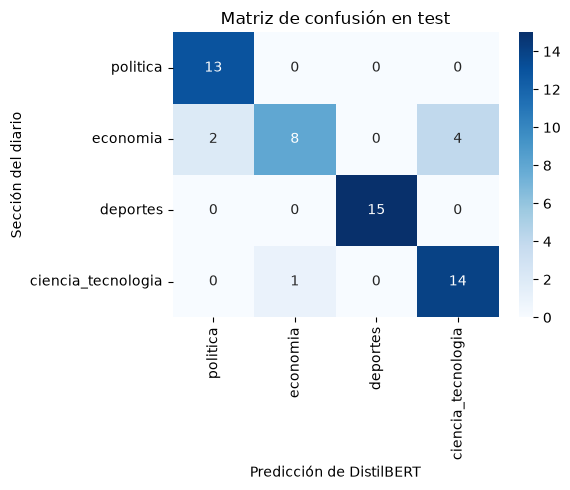

In [20]:
fig, eje = plt.subplots(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_real, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, ax=eje)
eje.set_xlabel("Predicción de DistilBERT")
eje.set_ylabel("Sección del diario")
eje.set_title("Matriz de confusión en test")
plt.tight_layout()
plt.show()

In [21]:
test_errores = test.assign(prediccion=[ETIQUETAS[i] for i in y_pred])
test_errores.loc[test_errores["etiqueta"] != test_errores["prediccion"],
                 ["titular", "etiqueta", "etiqueta_llm", "prediccion"]]

,titular,etiqueta,etiqueta_llm,prediccion
333,Ciberamenazas en América Latina: Perú registró mayor actividad de malware en el primer semestre de 2026,ciencia_tecnologia,ciencia_tecnologia,economia
171,El precio del petróleo brent baja a US$103 luego de que Trump afirmara que no atacará Irán antes de las elecciones d...,economia,economia,politica
167,"BTS en Lima: cómo 118 mil fans pueden mover hasta S/200 millones entre merchandising, restaurantes y más en el conc...",economia,economia,ciencia_tecnologia
162,Gamarra: pérdidas se elevan a S/1.000 millones por el fenómeno de El Niño,economia,economia,ciencia_tecnologia
109,"‘OxI Exprés’: obras para enfrentar El Niño aún no tienen convenios suscritos, ¿por qué?",economia,economia,ciencia_tecnologia
122,"Mario Gonzales, CEO de Luz del Sur: “Nuestra intención es llevar la medición inteligente a todos los clientes”",economia,ciencia_tecnologia,ciencia_tecnologia
100,Gobierno designa presidenta del directorio y directora ejecutiva del Fonafe,economia,politica,politica


### Reflexión por categoría

Con 57 titulares de test, cada titular mal clasificado mueve el F1 en casi 2 puntos. En ejecuciones de prueba el F1 macro de test varió entre 0,87 y 0,91 por pequeñas diferencias numéricas de la GPU, así que diferencias de pocos puntos no deben leerse como cambios reales. Se reporta la ejecución final de este notebook.

**Deportes** es la mejor categoría, con un F1 de 1,000. Sus titulares tienen un vocabulario muy propio, con nombres de clubes, jugadores y torneos como Cristal, Mbappé o Champions League, que casi no aparece en otras secciones. **Política** llega a 0,929. Reconoce todas sus noticias, pero recibe algunas de economía que mencionan al Gobierno o a políticos, como el nombramiento en el Fonafe o la caída del petróleo tras una declaración de Trump.

**Economía** es la más difícil, con 0,696, y el modelo solo reconoce 8 de sus 14 noticias. Es una categoría transversal que comparte vocabulario con las demás. Las pérdidas de Gamarra por El Niño o las obras para enfrentarlo hablan de clima y se confunden con ciencia, y lo que mueven los fans de BTS en Lima parece una noticia de entretenimiento. Dos de los siete errores vienen del LLM. En esos casos el LLM ya había etiquetado mal la noticia y el modelo aprendió su criterio, que es el costo de entrenar con supervisión débil. Uno de ellos es un nombramiento en el Fonafe, el mismo tipo de error que se encontró en la auditoría con el nombramiento en Indecopi.

**Ciencia y tecnología** queda en 0,848. Recibe varias noticias de economía y su único error propio es la nota sobre la actividad de malware en el Perú, que el modelo asocia con economía.

## 6. Comparación y decisión

Para comparar en igualdad de condiciones, los tres métodos se miden sobre **los mismos 57 titulares de test** y contra la sección del diario. También se mide cuánto tarda cada uno en clasificar un titular en la GPU.

In [22]:
import time

def ms_por_titular(funcion, textos):
    inicio = time.perf_counter()
    for texto in textos:
        funcion(texto)
    return (time.perf_counter() - inicio) / len(textos) * 1000

# LLM. Sus etiquetas de test ya existen, solo medimos el tiempo
ms_llm = ms_por_titular(lambda i: clasificar_llm(test.loc[i, "titular"], test.loc[i, "bajada"]), test.index)
parametros_llm = sum(p.numel() for p in llm.parameters())
del llm
torch.cuda.empty_cache()

# Zero-shot sobre el mismo test
zero_shot = pipeline("zero-shot-classification", model="joeddav/xlm-roberta-large-xnli",
                     device=0 if torch.cuda.is_available() else -1)
pred_zs_test = [de_nombre_a_etiqueta[zero_shot(t, candidate_labels=candidatas)["labels"][0]]
                for t in test["titular"]]
ms_zs = ms_por_titular(lambda t: zero_shot(t, candidate_labels=candidatas), test["titular"])
parametros_zs = sum(p.numel() for p in zero_shot.model.parameters())

# DistilBERT ajustado, como se usará en el dashboard
clasificador = pipeline("text-classification", model="modelo", tokenizer="modelo",
                        device=0 if torch.cuda.is_available() else -1)
ms_ft = ms_por_titular(clasificador, test["titular"])
parametros_ft = sum(p.numel() for p in clasificador.model.parameters())

def fila(metodo, pred, ms, parametros, entrena):
    return {"método": metodo,
            "accuracy": accuracy_score(test["etiqueta"], pred),
            "F1 macro": f1_score(test["etiqueta"], pred, average="macro"),
            "ms por titular": ms,
            "millones de parámetros": parametros / 1e6,
            "necesita entrenamiento": entrena}

comparacion = pd.DataFrame([
    fila("Zero-shot xlm-roberta-large-xnli", pred_zs_test, ms_zs, parametros_zs, "no"),
    fila("LLM Qwen2.5-1.5B, titular y bajada", test["etiqueta_llm"], ms_llm, parametros_llm, "no"),
    fila("DistilBERT ajustado, solo titular", [ETIQUETAS[i] for i in y_pred], ms_ft, parametros_ft, "sí, 12 s"),
]).round(3)
comparacion

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,método,accuracy,F1 macro,ms por titular,millones de parámetros,necesita entrenamiento
0,Zero-shot xlm-roberta-large-xnli,0.702,0.691,62.080,559.894,no
1,"LLM Qwen2.5-1.5B, titular y bajada",0.930,0.927,44.482,1543.714,no
2,"DistilBERT ajustado, solo titular",0.877,0.868,4.362,135.328,"sí, 12 s"


**Decisión.** El LLM es el más preciso, con un F1 macro de 0,927, pero también el más pesado. Necesita la bajada además del titular, tiene 1.544 millones de parámetros y requiere una GPU. En esta ejecución tardó unos 44 milisegundos por titular. El zero-shot no necesita entrenamiento, pero es el que peor clasifica, con 0,691.

DistilBERT ajustado queda 6 puntos por debajo del LLM, pero clasifica solo con el titular, tardó unos 4 milisegundos por titular y tiene 135 millones de parámetros, así que puede correr en CPU dentro de un dashboard. Para un entorno real se elegiría **DistilBERT ajustado**, por su costo y su velocidad. El LLM rinde más en lo que se usó aquí, que es etiquetar una sola vez los datos de entrenamiento, y podría reservarse para revisar los titulares en los que DistilBERT tenga poca confianza.

Resumen para la entrega, con las métricas pedidas.

In [23]:
print(f"F1 Macro: {f1_ft:.3f} | Zero-shot: {f1_zs:.3f} | Acuerdo LLM-Humano: {aciertos}/{len(revisada)}")

F1 Macro: 0.868 | Zero-shot: 0.708 | Acuerdo LLM-Humano: 19/20
